In [1]:


import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import scipy.stats
import sklearn


import sklearn.pipeline
import sklearn.impute
import sklearn.linear_model
import sklearn.dummy
import sklearn.metrics



print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("SciPy version:", scipy.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("All libraries imported successfully!")


Pandas version: 3.1.1
NumPy version: 2.5.5
SciPy version: 1.18.1
Scikit-learn version: 1.9.1
All libraries imported successfully!


In [2]:


df = pd.read_csv("energydata_clean.csv")


df["date"] = pd.to_datetime(df["date"])


if "hour" not in df.columns:
    df["hour"] = df["date"].dt.hour


if "day_night" not in df.columns:
    df["day_night"] = np.where(
        df["hour"].between(6, 21),
        "Day",
        "Night"
    )


display(df.head())


print("Dataset dimensions:", df.shape)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,hour,day_night
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,17,Day
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,17,Day
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,17,Day
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,17,Day
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,17,Day


Dataset dimensions: (19735, 29)


Summary Statistics

Descriptive statistics were calculated to understand household appliance energy consumption. The Appliances column was selected because it represents household appliance energy usage.

The analysis includes count, mean, median, standard deviation, variance, minimum, maximum, range, quartiles, and interquartile range.

In [3]:


appliances = df["Appliances"]


summary = pd.DataFrame({
    "Statistic": [
        "Count",
        "Mean",
        "Median",
        "Standard Deviation",
        "Variance",
        "Minimum",
        "Maximum",
        "Range",
        "Q1",
        "Q3",
        "IQR"
    ],

    "Value": [
        appliances.count(),
        np.mean(appliances),
        np.median(appliances),
        np.std(appliances, ddof=1),
        np.var(appliances, ddof=1),
        np.min(appliances),
        np.max(appliances),
        np.max(appliances) - np.min(appliances),
        np.percentile(appliances, 25),
        np.percentile(appliances, 75),
        np.percentile(appliances, 75) -
        np.percentile(appliances, 25)
    ]
})

display(summary.round(2))


,Statistic,Value
0,Count,19735.00
1,Mean,97.69
2,Median,60.00
3,Standard Deviation,102.52
4,Variance,10511.35
5,Minimum,10.00
6,Maximum,1080.00
7,Range,1070.00
8,Q1,50.00
9,Q3,100.00


Day vs Night Summary Statistics

The dataset was divided into daytime and nighttime observations to compare household appliance energy consumption.

The count, mean, median, and standard deviation were calculated for each period.

In [4]:


day_night_summary = df.groupby("day_night")["Appliances"].agg(
    ["count", "mean", "median", "std"]
).round(1)

display(day_night_summary)


,count,mean,median,std
day_night,,,,
Day,13159,119.7,80.0,118.1
Night,6576,53.7,50.0,26.9


Interpretation

The results show that average appliance consumption during the Day was 119.7 Wh, compared with 53.7 Wh during the Night.

The difference between the two averages is 66.0 Wh.

The daytime median was 80 Wh, while the nighttime median was 50 Wh. This indicates that typical appliance consumption was also higher during daytime.

The standard deviation was higher during the Day (118.1 Wh) than during the Night (26.9 Wh), indicating greater variation in daytime consumption.

Overall, the descriptive statistics suggest that household appliance consumption was higher during daytime.

Data Cleaning Steps

The dataset was prepared during Step 2 before this analysis. Each step is listed below with the reason it was done. The code cell directly below this one prints the checks so the counts are visible in this notebook.

1. **Date conversion:** The date column was converted to datetime format so the data can be sorted in time order and grouped by date and hour.
2. **Missing-value check:** The dataset was checked for missing values because Linear Regression cannot handle them. The count is printed below, and the model cell also stops with an error if any remain.
3. **Duplicate check:** Rows that are identical in every column would be repeated entries that count the same reading twice. The number of duplicate rows (and repeated timestamps) is printed below.
4. **Hour feature:** An hour column was created from the date to study how consumption changes through the day.
5. **Day/Night feature:** A day_night column was created. Readings from 6:00 AM to 9:59 PM are Day and readings from 10:00 PM to 5:59 AM are Night, so consumption can be compared between the two periods.
6. **Removal of rv1 and rv2:** These columns are random numbers by design in the source data, so they carry no real household or weather information. Keeping them could only add noise to the model.
7. **Outlier examination:** The IQR rule (values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR) was used to flag outliers. The number flagged is printed below. These high readings were **kept** because they are plausible real usage spikes (for example, several appliances running at once) and not sensor errors, and removing them would hide real behavior. Because they affect the mean much more than the median, the median and the Wilcoxon test are used alongside the mean and t-test.

Results of the checks: no duplicate rows and no missing values were found, so none were removed or handled (duplicates removed = 0, missing values handled = 0).

After cleaning, the dataset has 19,735 observations and 29 columns.

In [5]:

appliances = df["Appliances"]

print("Rows, columns:", df.shape)
print("Total missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Repeated timestamps:", int(df["date"].duplicated().sum()))
print("rv1/rv2 still in data:", [c for c in ["rv1", "rv2"] if c in df.columns])


q1, q3 = np.percentile(appliances, [25, 75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = appliances[(appliances < lower) | (appliances > upper)]

print(f"\nIQR outlier bounds: {lower:.1f} to {upper:.1f} Wh")
print(f"Outliers flagged: {len(outliers)} ({len(outliers) / len(appliances):.1%} of rows)")
print(f"Largest reading: {appliances.max()} Wh")


trimmed = appliances[(appliances >= lower) & (appliances <= upper)]
print(f"\nMean with all rows: {appliances.mean():.1f} Wh | without outliers: {trimmed.mean():.1f} Wh")
print(f"Median with all rows: {appliances.median():.1f} Wh | without outliers: {trimmed.median():.1f} Wh")

Rows, columns: (19735, 29)
Total missing values: 0
Duplicate rows: 0
Repeated timestamps: 0
rv1/rv2 still in data: []

IQR outlier bounds: -25.0 to 175.0 Wh
Outliers flagged: 2138 (10.8% of rows)
Largest reading: 1080 Wh

Mean with all rows: 97.7 Wh | without outliers: 67.2 Wh
Median with all rows: 60.0 Wh | without outliers: 60.0 Wh


Statistical Test: Day vs Night Appliance Consumption

A paired-samples t-test was selected to determine whether daily average appliance consumption differs between daytime and nighttime. Each pair consists of the Day and Night average from the same date.

Null Hypothesis (H0): There is no difference between the average daily Day and Night consumption.

Alternative Hypothesis (H1): There is a difference between the average daily Day and Night consumption.

The significance level is 0.05. Because the data begin at 17:00 on January 11 and end at 18:00 on May 27, those boundary dates do not contain complete Day/Night windows and are excluded from the paired analysis.

**Assumptions of the paired t-test**

1. **Paired data:** each date gives one Day average and one Night average. Met.
2. **Independent pairs:** daily averages are closer to independent than 10-minute readings, but neighboring days may be related, so full independence cannot be guaranteed.
3. **Approximately normal differences:** checked with a histogram and the Shapiro-Wilk test below. This assumption is **not met** (Shapiro-Wilk p < 0.001). To handle this, a Wilcoxon signed-rank test (no normality required) and a bootstrap confidence interval are reported as robustness checks. With 136 pairs the t-test is also fairly robust to moderate non-normality. The conclusion is trusted only if all methods agree.

In [6]:
daily_averages = (
    df.groupby([df["date"].dt.date, "day_night"])["Appliances"]
    .mean()
    .unstack()
)

daily_averages = daily_averages.dropna(
    subset=["Day", "Night"]
)


daily_averages = daily_averages.iloc[1:-1]

display(daily_averages.head(10))

print("Number of complete paired dates:", len(daily_averages))


day_night,Day,Night
date,,
2016-01-12,93.020833,71.041667
2016-01-13,119.479167,52.083333
2016-01-14,205.937500,42.291667
2016-01-15,151.979167,72.083333
2016-01-16,156.875000,62.083333
2016-01-17,188.750000,50.625000
2016-01-18,118.854167,44.166667
2016-01-19,102.812500,44.166667
2016-01-20,144.791667,53.750000


Number of complete paired dates: 136


Mean difference (Day - Night): 65.8624387254902
Median difference: 56.97916666666667
Standard deviation: 45.32444356426009
Dates when Day was higher: 133 of 136


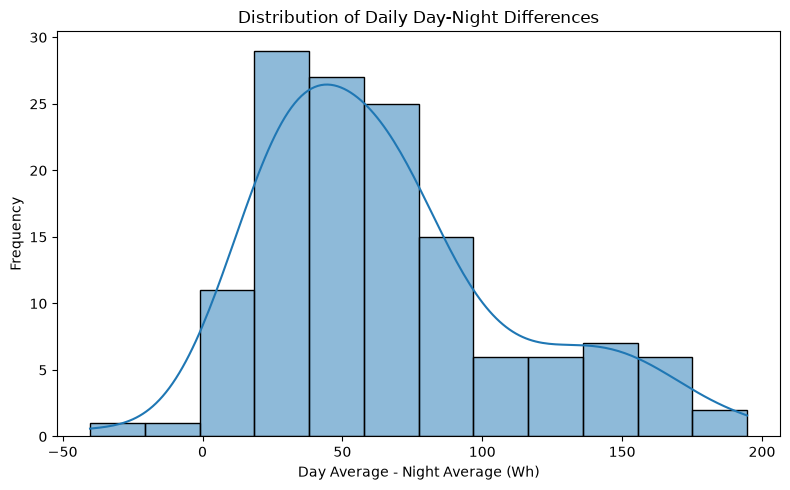

Shapiro-Wilk statistic: 0.9366810662816311
Shapiro-Wilk p-value: 7.966443754646044e-06
The daily differences are not normally distributed (Shapiro-Wilk p < 0.001).


In [7]:
differences = (
    daily_averages["Day"] -
    daily_averages["Night"]
)

print("Mean difference (Day - Night):", np.mean(differences))
print("Median difference:", np.median(differences))
print("Standard deviation:", np.std(differences, ddof=1))


day_higher_count = (differences > 0).sum()
print("Dates when Day was higher:", day_higher_count, "of", len(differences))


plt.figure(figsize=(8, 5))
sns.histplot(differences, kde=True)
plt.title("Distribution of Daily Day-Night Differences")
plt.xlabel("Day Average - Night Average (Wh)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

shapiro_stat, shapiro_p = scipy.stats.shapiro(differences)
print("Shapiro-Wilk statistic:", shapiro_stat)
print("Shapiro-Wilk p-value:", shapiro_p)

if shapiro_p < 0.001:
    print(
        "The daily differences are not normally distributed "
        "(Shapiro-Wilk p < 0.001)."
    )
else:
    print("The Shapiro-Wilk test did not indicate a departure from normality.")


In [8]:
t_statistic, p_value = scipy.stats.ttest_rel(
    daily_averages["Day"],
    daily_averages["Night"]
)

print("T-statistic:", t_statistic)
print("P-value:", p_value)


wilcoxon_statistic, wilcoxon_p = scipy.stats.wilcoxon(
    daily_averages["Day"],
    daily_averages["Night"]
)
print("Wilcoxon signed-rank statistic:", wilcoxon_statistic)
print("Wilcoxon signed-rank p-value:", wilcoxon_p)

alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("There is a statistically significant difference between Day and Night averages.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a statistically significant difference.")

if wilcoxon_p < alpha:
    print("The Wilcoxon test also indicates a statistically significant paired difference.")
else:
    print("The Wilcoxon test does not indicate a statistically significant paired difference.")

print()
if shapiro_p < alpha and wilcoxon_p < alpha:
    print(
        "Assumption check: the normality assumption was not met (Shapiro-Wilk), "
        "but the Wilcoxon test, which does not require normality, reaches the "
        "same conclusion. With 136 pairs the t-test is also fairly robust, so "
        "the conclusion is supported."
    )
elif shapiro_p < alpha:
    print(
        "Assumption check: the normality assumption was not met and the Wilcoxon "
        "test does not agree with the t-test. Rely on the Wilcoxon result and "
        "interpret the t-test cautiously."
    )
else:
    print("Assumption check: the normality assumption was met.")

T-statistic: 16.94629571529298
P-value: 3.1247391238532203e-35
Wilcoxon signed-rank statistic: 50.0
Wilcoxon signed-rank p-value: 1.3861500033964865e-23
Reject the null hypothesis.
There is a statistically significant difference between Day and Night averages.
The Wilcoxon test also indicates a statistically significant paired difference.

Assumption check: the normality assumption was not met (Shapiro-Wilk), but the Wilcoxon test, which does not require normality, reaches the same conclusion. With 136 pairs the t-test is also fairly robust, so the conclusion is supported.


In [9]:
mean_difference = float(np.mean(differences))
n = len(differences)
standard_error = scipy.stats.sem(differences)

ci_low, ci_high = scipy.stats.t.interval(
    confidence=0.95,
    df=n - 1,
    loc=mean_difference,
    scale=standard_error
)

rng = np.random.default_rng(42)
diff_values = differences.to_numpy()
boot_means = np.array([
    rng.choice(diff_values, size=n, replace=True).mean()
    for _ in range(10000)
])
boot_low, boot_high = np.percentile(boot_means, [2.5, 97.5])

print(f"Mean difference (Day - Night): {mean_difference:.2f} Wh")
print(f"95% CI (t-based):    {ci_low:.1f} to {ci_high:.1f} Wh")
print(f"95% CI (bootstrap):  {boot_low:.1f} to {boot_high:.1f} Wh")

print(
    f"\nInterpretation: Daytime appliance consumption was, on average, "
    f"{mean_difference:.1f} Wh higher than nighttime consumption. "
    f"The 95% confidence interval ranges from {ci_low:.1f} to {ci_high:.1f} Wh "
    f"(bootstrap: {boot_low:.1f} to {boot_high:.1f} Wh)."
)
print(
    "Both intervals exclude zero, which is consistent with a statistically "
    "significant Day-Night difference. The bootstrap interval is included "
    "because the paired differences are not normally distributed."
)

Mean difference (Day - Night): 65.86 Wh
95% CI (t-based):    58.2 to 73.5 Wh
95% CI (bootstrap):  58.2 to 73.7 Wh

Interpretation: Daytime appliance consumption was, on average, 65.9 Wh higher than nighttime consumption. The 95% confidence interval ranges from 58.2 to 73.5 Wh (bootstrap: 58.2 to 73.7 Wh).
Both intervals exclude zero, which is consistent with a statistically significant Day-Night difference. The bootstrap interval is included because the paired differences are not normally distributed.


Machine Learning: Predicting Appliance Consumption from Conditions

The objective is to predict the current Appliances reading using the conditions named in the proposal: indoor temperature and humidity, outdoor weather, and time of day. The target is the current Appliances value, not the next 10-minute reading.

The Appliances target is excluded from the predictors to prevent the model from using the answer as an input. The lights variable is also excluded from the main model because it is another electricity-use measurement rather than an environmental or time-of-day condition. Day/Night dummy variables are retained. The data are sorted by date and divided chronologically, with the first 80% used for training and the final 20% used for testing.


In [10]:
model_df = df.sort_values("date").copy()

features = [
    "T1", "RH_1", "T2", "RH_2",
    "T3", "RH_3", "T4", "RH_4",
    "T5", "RH_5", "T6", "RH_6",
    "T7", "RH_7", "T8", "RH_8",
    "T9", "RH_9",
    "T_out", "Press_mm_hg", "RH_out",
    "Windspeed", "Visibility", "Tdewpoint",
    "hour"
]


features = [column for column in features if column in model_df.columns]

X = model_df[features].copy()


day_night_encoded = pd.get_dummies(
    model_df["day_night"],
    prefix="period",
    drop_first=True,
    dtype=int
)
X = pd.concat([X, day_night_encoded], axis=1)


y = model_df["Appliances"]

print("Predictor columns:", list(X.columns))
print("Number of predictors:", X.shape[1])
print("Number of observations:", len(X))
print("Target: current Appliances reading")
print("Excluded predictors: Appliances (target), lights, rv1, rv2")
print("Missing predictor values:", int(X.isna().sum().sum()))
if X.isna().any().any():
    raise ValueError(
        "Predictor columns contain missing values. Complete the cleaning "
        "or add an imputation step before fitting Linear Regression."
    )



Predictor columns: ['T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'hour', 'period_Night']
Number of predictors: 26
Number of observations: 19735
Target: current Appliances reading
Excluded predictors: Appliances (target), lights, rv1, rv2
Missing predictor values: 0


In [11]:

split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index]
y_train = y.iloc[:split_index]

X_test = X.iloc[split_index:]
y_test = y.iloc[split_index:]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training period:", model_df["date"].iloc[0], "to", model_df["date"].iloc[split_index - 1])
print("Testing period:", model_df["date"].iloc[split_index], "to", model_df["date"].iloc[-1])


Training observations: 15788
Testing observations: 3947
Training period: 2016-01-11 17:00:00 to 2016-04-30 08:10:00
Testing period: 2016-04-30 08:20:00 to 2016-05-27 18:00:00


In [12]:

model = sklearn.linear_model.LinearRegression()

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [13]:
baseline = sklearn.dummy.DummyRegressor(
    strategy="mean"
)

baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

print("Mean baseline model trained successfully!")


Mean baseline model trained successfully!


In [14]:
comparison = pd.DataFrame({
    "Metric": [
        "MAE",
        "RMSE",
        "R-squared"
    ],
    "Linear Regression": [
        sklearn.metrics.mean_absolute_error(y_test, predictions),
        np.sqrt(sklearn.metrics.mean_squared_error(y_test, predictions)),
        sklearn.metrics.r2_score(y_test, predictions)
    ],
    "Baseline": [
        sklearn.metrics.mean_absolute_error(y_test, baseline_predictions),
        np.sqrt(sklearn.metrics.mean_squared_error(y_test, baseline_predictions)),
        sklearn.metrics.r2_score(y_test, baseline_predictions)
    ]
})

display(comparison.round(3))

train_rmse = np.sqrt(
    sklearn.metrics.mean_squared_error(y_train, model.predict(X_train))
)
test_rmse = np.sqrt(
    sklearn.metrics.mean_squared_error(y_test, predictions)
)
baseline_test_rmse = np.sqrt(
    sklearn.metrics.mean_squared_error(y_test, baseline_predictions)
)

print("Train RMSE:", train_rmse)
print("Test RMSE:", test_rmse)
print("Baseline Test RMSE:", baseline_test_rmse)
print("Train-Test RMSE gap:", test_rmse - train_rmse)

if test_rmse < baseline_test_rmse:
    print(
        "Interpretation: The Linear Regression model has a lower test RMSE "
        "than the mean baseline, so it predicts better than the baseline "
        "on this chronological test set."
    )
else:
    print(
        "Interpretation: The Linear Regression model does not achieve a "
        "lower test RMSE than the mean baseline. The available predictors "
        "do not improve on the baseline in this test period."
    )

if train_rmse < test_rmse:
    print(
        "The training RMSE is lower than the test RMSE. This performance gap "
        "may indicate that the model fits the training data better than "
        "unseen later observations."
    )
else:
    print(
        "The training RMSE is not lower than the test RMSE. Review both "
        "values when assessing generalization."
    )

print("\nPlain-language model interpretation:")
if test_rmse < baseline_test_rmse:
    print(
        f"The model's test RMSE ({test_rmse:.2f} Wh) is lower than the "
        f"mean-baseline test RMSE ({baseline_test_rmse:.2f} Wh), so the "
        "conditions-and-time model performs better than the baseline "
        "on the held-out period."
    )
else:
    print(
        f"The model's test RMSE ({test_rmse:.2f} Wh) is not lower than the "
        f"mean-baseline test RMSE ({baseline_test_rmse:.2f} Wh), so it does "
        "not outperform the baseline on the held-out period."
    )
print(
    f"The model's test R-squared is {sklearn.metrics.r2_score(y_test, predictions):.3f}. "
    f"The training-to-test RMSE gap is {test_rmse - train_rmse:.2f} Wh. "
    "A larger positive gap indicates worse performance on later unseen data."
)

,Metric,Linear Regression,Baseline
0,MAE,49.057,52.685
1,RMSE,84.769,91.053
2,R-squared,0.133,-0.000


Train RMSE: 94.89758041119828
Test RMSE: 84.76905191123593
Baseline Test RMSE: 91.05343511602582
Train-Test RMSE gap: -10.128528499962343
Interpretation: The Linear Regression model has a lower test RMSE than the mean baseline, so it predicts better than the baseline on this chronological test set.
The training RMSE is not lower than the test RMSE. Review both values when assessing generalization.

Plain-language model interpretation:
The model's test RMSE (84.77 Wh) is lower than the mean-baseline test RMSE (91.05 Wh), so the conditions-and-time model performs better than the baseline on the held-out period.
The model's test R-squared is 0.133. The training-to-test RMSE gap is -10.13 Wh. A larger positive gap indicates worse performance on later unseen data.


In [15]:
r2_test = sklearn.metrics.r2_score(y_test, predictions)
rmse_gap = test_rmse - train_rmse

print("QUESTION 3 — RESULTS TO REPORT")
print(
    f"Linear Regression test RMSE = {test_rmse:.2f} Wh; "
    f"mean-baseline test RMSE = {baseline_test_rmse:.2f} Wh; "
    f"test R-squared = {r2_test:.3f}; "
    f"training RMSE = {train_rmse:.2f} Wh; "
    f"test-minus-training RMSE gap = {rmse_gap:.2f} Wh."
)
if test_rmse < baseline_test_rmse:
    print(
        "Conclusion: the conditions-and-time model outperforms the mean "
        "baseline on the chronological test set."
    )
else:
    print(
        "Conclusion: the conditions-and-time model does not outperform "
        "the mean baseline on the chronological test set."
    )


QUESTION 3 — RESULTS TO REPORT
Linear Regression test RMSE = 84.77 Wh; mean-baseline test RMSE = 91.05 Wh; test R-squared = 0.133; training RMSE = 94.90 Wh; test-minus-training RMSE gap = -10.13 Wh.
Conclusion: the conditions-and-time model outperforms the mean baseline on the chronological test set.


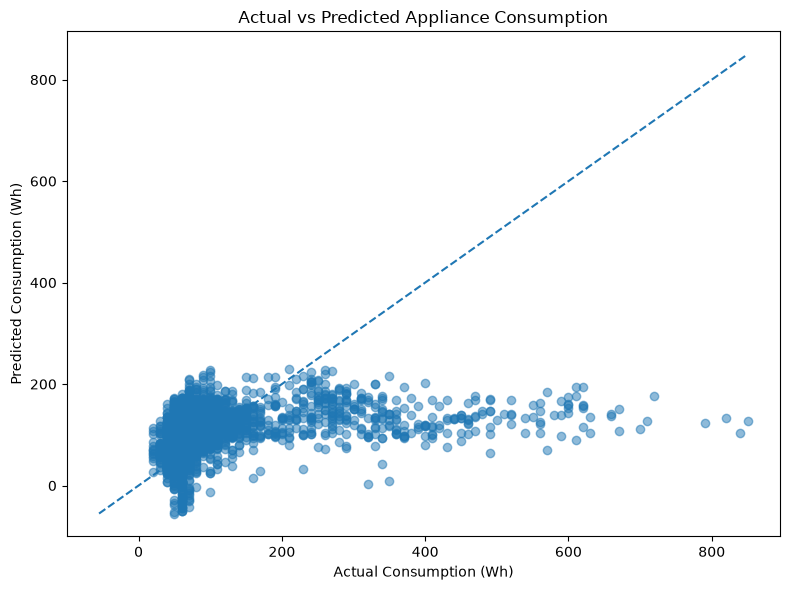

In [16]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    predictions,
    alpha=0.5
)

minimum = min(y_test.min(), predictions.min())
maximum = max(y_test.max(), predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title("Actual vs Predicted Appliance Consumption")
plt.xlabel("Actual Consumption (Wh)")
plt.ylabel("Predicted Consumption (Wh)")

plt.tight_layout()
plt.show()


Relationship Between Appliance Consumption and Other Variables

Pearson correlations were calculated between Appliances and all available numerical variables. The variables are ranked from the most negative to the most positive correlation.

Correlation indicates the strength and direction of a linear association. A weak correlation does not mean that a variable has no possible relationship with appliance consumption, and correlation does not establish causation.

The ranking helps identify which measured conditions or related variables have the strongest linear associations with appliance consumption.


Correlation ranking (lowest to highest):
RH_out        -0.15
RH_8          -0.09
RH_6          -0.08
RH_2          -0.06
RH_7          -0.06
RH_9          -0.05
Press_mm_hg   -0.03
Visibility     0.00
RH_5           0.01
T9             0.01
Tdewpoint      0.02
RH_4           0.02
T5             0.02
T7             0.03
RH_3           0.04
T8             0.04
T4             0.04
T1             0.06
T3             0.09
RH_1           0.09
Windspeed      0.09
T_out          0.10
T6             0.12
T2             0.12
lights         0.20
hour           0.22
Name: Appliances, dtype: float64


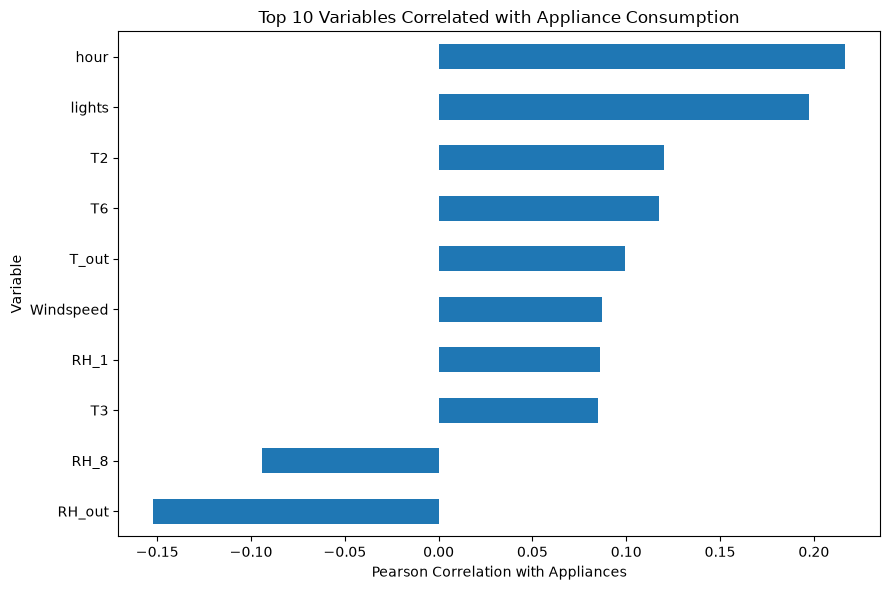

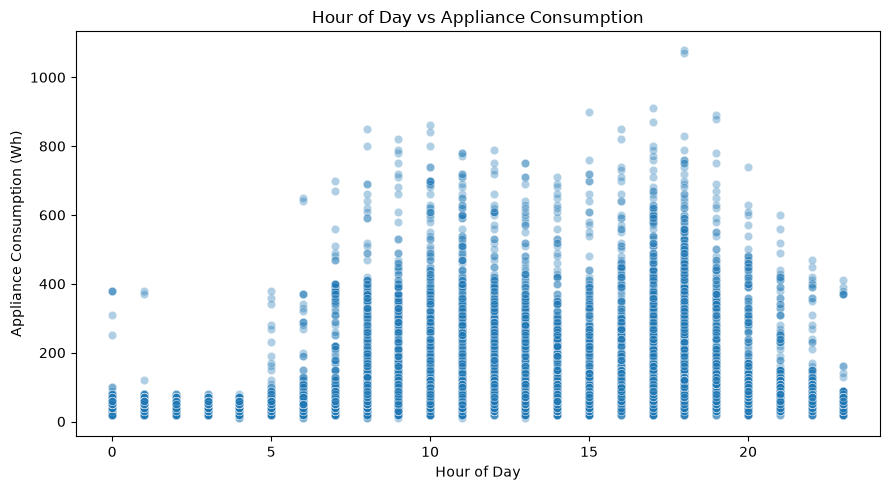

In [17]:

corr = (
    df.corr(numeric_only=True)["Appliances"]
    .drop("Appliances")
    .sort_values()
)

print("Correlation ranking (lowest to highest):")
print(corr.round(2))


top_correlations = corr.reindex(
    corr.abs().sort_values(ascending=False).index
).head(10).sort_values()

plt.figure(figsize=(9, 6))
top_correlations.plot(kind="barh")
plt.title("Top 10 Variables Correlated with Appliance Consumption")
plt.xlabel("Pearson Correlation with Appliances")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()


plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df,
    x="hour",
    y="Appliances",
    alpha=0.35
)
plt.title("Hour of Day vs Appliance Consumption")
plt.xlabel("Hour of Day")
plt.ylabel("Appliance Consumption (Wh)")
plt.tight_layout()
plt.show()


Interpretation for Question 2

The strongest linear associations with appliance consumption are hour of day (r = +0.22), lights (r = +0.20), and outdoor relative humidity, RH_out (r = −0.15). These are all weak correlations, so none of the individual variables has a strong linear relationship with appliance consumption. Hour and lights are positively associated with consumption, while outdoor humidity is negatively associated. These findings describe associations only and do not establish cause and effect.

Note: lights is included in this correlation analysis because Question 2 asks which measured variables are most associated with Appliances. However, lights is excluded from the main Question 3 prediction model because it is an electricity-use measurement rather than one of the proposed environmental/time conditions.


Correlation, Causation, Data Leakage, and Overfitting

**Correlation versus causation.** Correlation only shows that two variables move together. It does not show that one causes the other. The strongest correlations here are weak (hour r = +0.22, lights r = +0.20, RH_out r = −0.15). Hour of day is probably a stand-in for something that was not measured, such as people being home and active, so changing the hour would not change appliance use by itself.

**Data leakage.** Leakage happens when the model is given information it would not have in real use. To avoid it, the target (Appliances) is not a predictor, and lights is excluded because it is another electricity-use measurement. rv1 and rv2 were removed in cleaning. The data were split by time (first 80% train, last 20% test), so the model is never trained on readings from after the period it is tested on. The mean baseline is also fitted on the training data only.

**Overfitting.** Overfitting means the model fits the training data well but does worse on new data. We checked this by comparing training RMSE (94.90 Wh) with test RMSE (84.77 Wh) and by comparing the model with the mean baseline on the test set. The test error is not higher than the training error, so there is no sign of overfitting. Linear Regression with 26 predictors and 15,788 training rows is also a simple model, and no tuning was done on the test set. The test error being lower than the training error is unusual, and a possible reason is that the test period (May) has fewer extreme spikes. Seasonal differences between the training and test periods may still limit how well the model works in other seasons.

Conclusion

**Question 1: Is appliance consumption different between Day and Night?**

Yes. Daytime appliance consumption was higher than nighttime consumption by 65.9 Wh per 10-minute reading (comparing daily Day and Night averages). The 95% confidence interval is 58.2 to 73.5 Wh (paired t-test p = 3.1 × 10⁻³⁵). Because the Shapiro-Wilk test showed the daily differences are not normally distributed, we also ran a Wilcoxon signed-rank test and a bootstrap confidence interval, neither of which requires normality. The Wilcoxon test was also significant, and the bootstrap 95% confidence interval was 58.2 to 73.7 Wh, which agrees with the t-based interval. Daytime consumption was higher on 133 of the 136 complete paired dates. Therefore, the analysis provides strong evidence that appliance consumption is higher during the Day.

**Question 2: Which variables are most associated with appliance consumption?**

The strongest correlations are hour of day (r = +0.22), lights (r = +0.20), and outdoor relative humidity (RH_out, r = −0.15). All three relationships are weak. Hour and lights have weak positive associations, while outdoor humidity has a weak negative association. Correlation does not establish causation.

**Question 3: Can indoor conditions, outdoor weather, and time of day predict appliance consumption better than the average?**

Yes, but only modestly. The model uses indoor temperature and humidity, outdoor weather measurements, hour, and the Day/Night indicator. It excludes the Appliances target and lights, so it tests the proposal's stated conditions and not another electricity-use measurement. It was trained on the first 80% of the data (15,788 rows) and tested on the final 20% (3,947 rows, April 30 to May 27).

On the test set, Linear Regression had an RMSE of 84.77 Wh compared with 91.05 Wh for the mean baseline, which is about 7% lower. Its MAE was 49.06 Wh versus 52.69 Wh for the baseline, and its R-squared was 0.133. So the model beats the baseline but explains only about 13% of the variation in appliance consumption. The training RMSE (94.90 Wh) was higher than the test RMSE, so there is no sign of overfitting.

**Limitation:** The test period is roughly May, whereas the training data cover winter and early spring, so seasonal differences may affect results. Linear Regression also treats hour as a straight-line predictor, although appliance use may follow a more complex daily pattern. Large usage spikes are hard to predict from these variables, which keeps the R-squared low.